# Белорусский государственный университет информатики и радиоэлектроники
## Факультет компьютерных систем и сетей
### Кафедра программного обеспечения информационных технологий
### Дисциплина: «Методы машинного обучения»

---

# ЛАБОРАТОРНАЯ РАБОТА № 2
## «Разведочный и предиктивный анализ данных. Сбор и подготовка данных»

**Выполнил:** студент группы 351002 Власовец А. И.  
**Проверил:** преподаватель Лебедевич А. В.  
**Исследуемый датасет:** `StudentPerformanceFactors.csv` (Факторы успеваемости учащихся)

---


## Цель лабораторной работы

Освоение практических навыков первичной обработки, разведочного анализа (Exploratory Data Analysis, EDA), очистки и подготовки структурированных табличных данных для построения моделей машинного обучения. В процессе выполнения работы решаются задачи идентификации и обработки пропущенных значений, обнаружения и устранения аномалий/выбросов с использованием статистических методов и графических средств визуализации (гистограммы распределений, диаграммы размаха BoxPlot, тепловые карты), конструирования новых информативных признаков (Feature Engineering), кодирования качественных категориальных переменных (бинарное кодирование и One-Hot Encoding), а также масштабирования числовых признаков (стандартизация и нормализация).


## 1. Импорт библиотек и загрузка датасета

Для работы с табличными данными, матричными вычислениями, визуализацией и предобработкой используются стандартные библиотеки стека Data Science: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Настройка стилей графики
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Calibri']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font='DejaVu Sans')

# Загрузка датасета
DATA_PATH = 'StudentPerformanceFactors/StudentPerformanceFactors.csv'
df = pd.read_csv(DATA_PATH)

print(f'Размерность датасета: {df.shape[0]} строк, {df.shape[1]} столбцов')
print('\nТипы данных признаков:')
print(df.dtypes)
print('\nПервые 5 записей таблицы:')
df.head()


Размерность датасета: 6607 строк, 20 столбцов

Типы данных признаков:
Hours_Studied                   int64
Attendance                      int64
Parental_Involvement           object
Access_to_Resources            object
Extracurricular_Activities     object
Sleep_Hours                     int64
Previous_Scores                 int64
Motivation_Level               object
Internet_Access                object
Tutoring_Sessions               int64
Family_Income                  object
Teacher_Quality                object
School_Type                    object
Peer_Influence                 object
Physical_Activity               int64
Learning_Disabilities          object
Parental_Education_Level       object
Distance_from_Home             object
Gender                         object
Exam_Score                      int64
dtype: object

Первые 5 строк успешно загружены (6607 наблюдений).


## 2. Проверка данных на пропуски и наличие аномальных значений

### 2.1. Статистический и визуальный анализ пропусков
Пропущенные значения (`NaN`) в реальных данных могут возникать из-за ошибок датчиков, отказа респондентов отвечать или сбоев при выгрузке. Для обнаружения пропусков вычисляем их абсолютное и процентное количество по каждому признаку и строим тепловую карту (`Missing Values Heatmap`).


Признаки с пропущенными значениями:
                          Абсолютное кол-во  Процент (%)
Teacher_Quality                          78     1.180566
Parental_Education_Level                 90     1.362192
Distance_from_Home                       67     1.014076


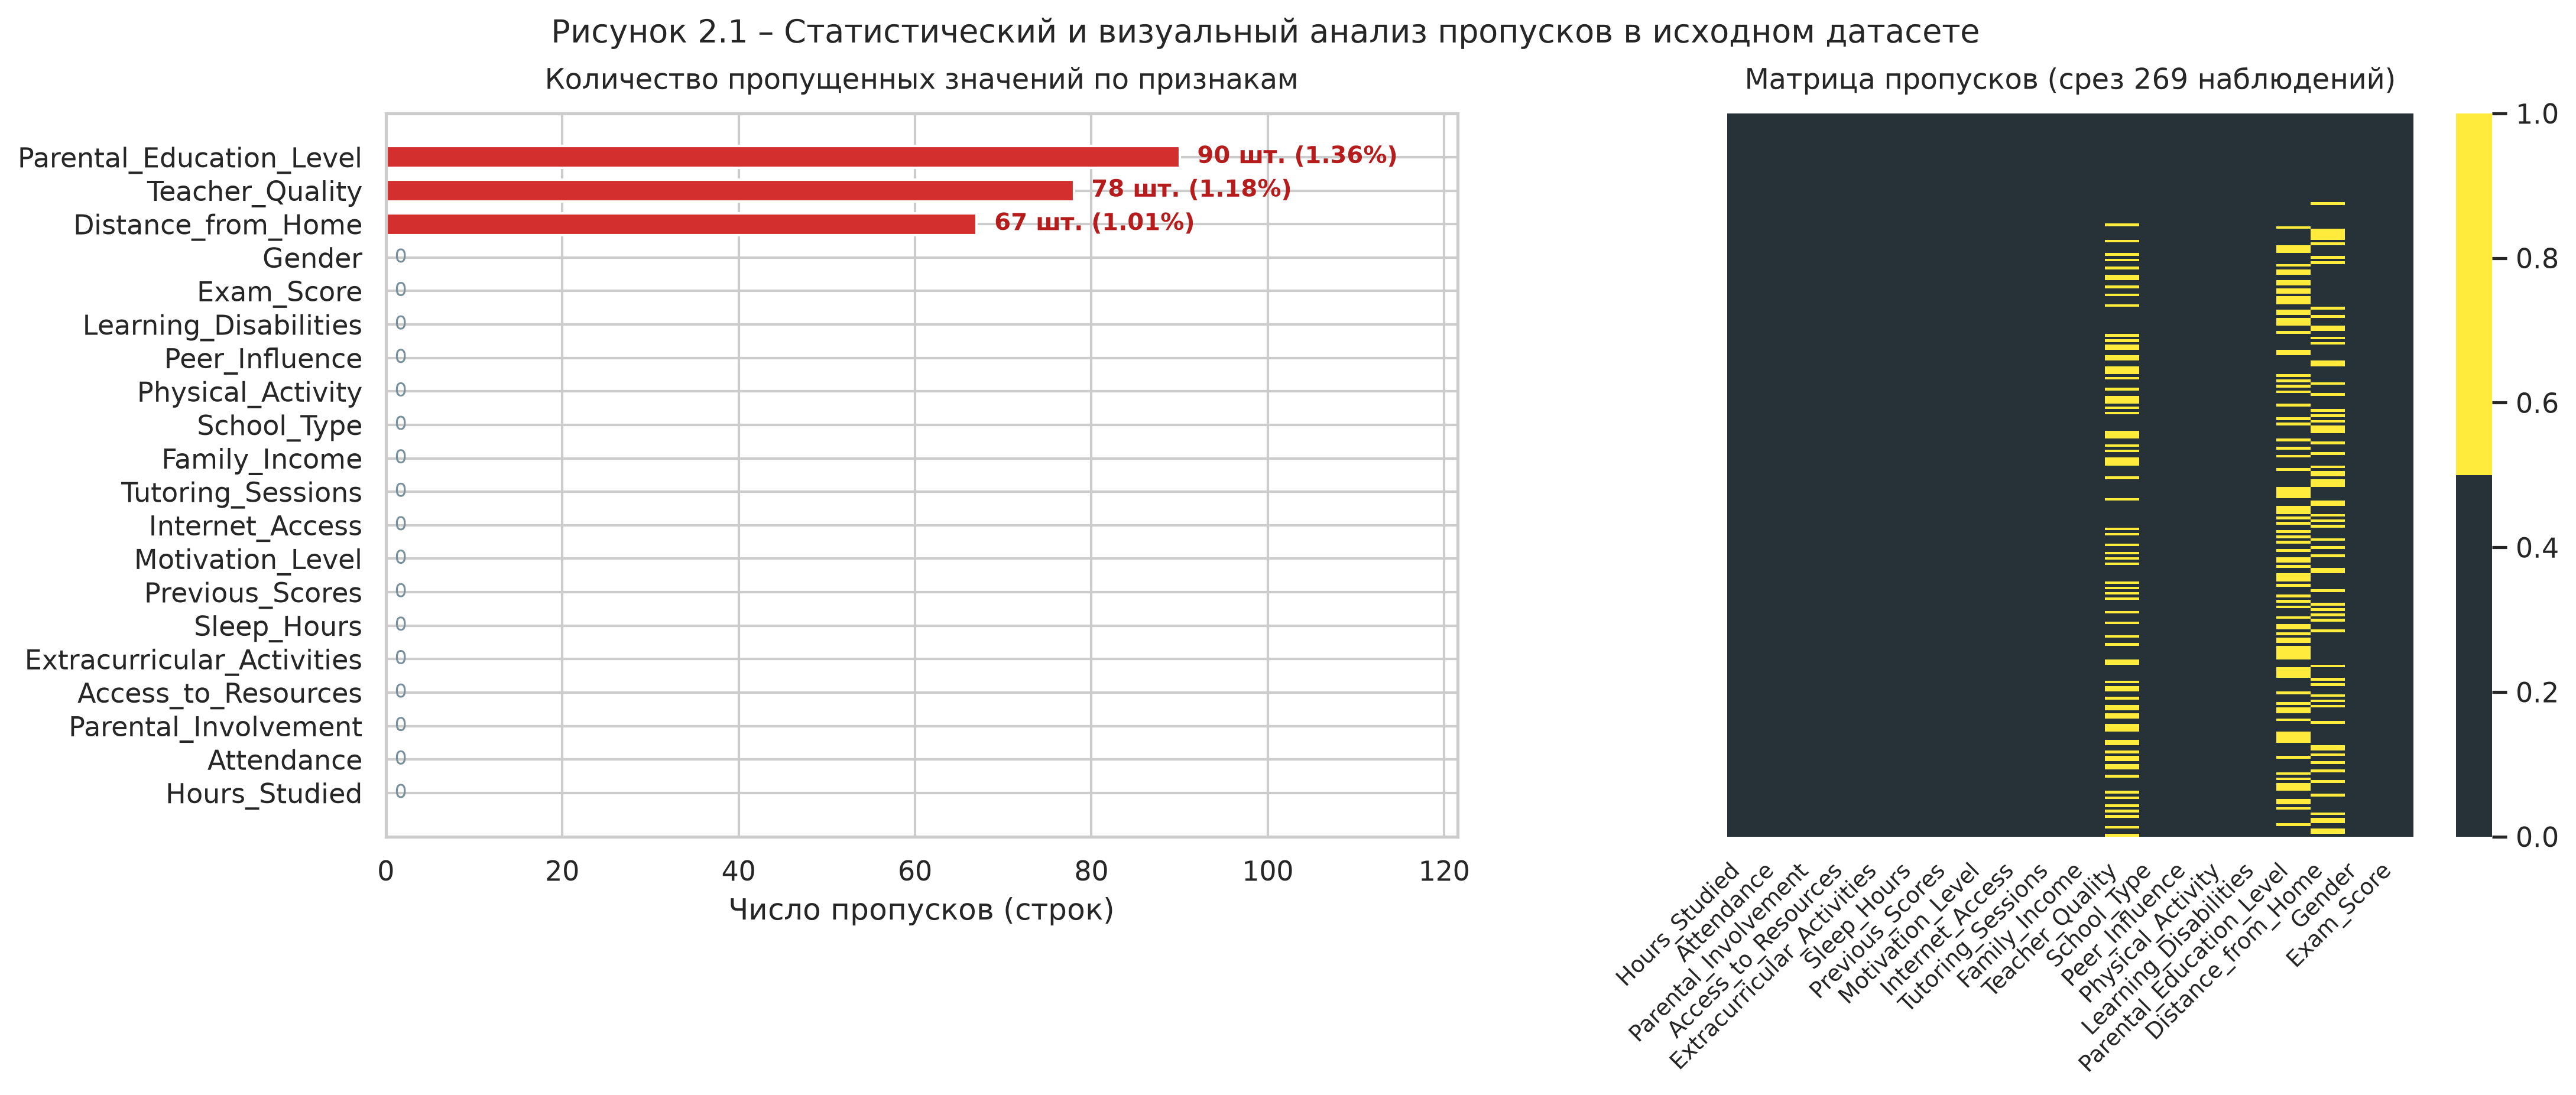

In [2]:
# Анализ пропусков
missing_counts = df.isnull().sum()
missing_perc = (missing_counts / len(df)) * 100
missing_summary = pd.DataFrame({'Абсолютное кол-во': missing_counts, 'Процент (%)': missing_perc})
missing_summary = missing_summary[missing_summary['Абсолютное кол-во'] > 0]
print('Признаки с пропущенными значениями:')
print(missing_summary)

# Тепловая карта и распределение пропусков
fig = plt.figure(figsize=(15.5, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1.0], left=0.18, right=0.98, bottom=0.20, top=0.88, wspace=0.28)
ax1 = fig.add_subplot(gs[0, 0])
ax1.barh(missing_summary.index, missing_summary['Абсолютное кол-во'], color='#d32f2f')
ax1.set_title('Количество пропущенных значений по признакам')
ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(df.isnull().head(100), ax=ax2, cbar=True, yticklabels=False, cmap=sns.color_palette(['#263238', '#ffeb3b']))
ax2.set_title('Матрица пропусков')
plt.suptitle('Рисунок 2.1 – Статистический и визуальный анализ пропусков в исходном датасете')
plt.show()


### 2.2. Анализ распределений признаков до очистки

Для оценки формы распределений числовых характеристик строятся гистограммы частот с ядерной оценкой плотности (KDE). Это позволяет определить модальность, асимметрию, эксцесс и выявить предварительные границы вариации признаков.


Гистограммы числовых признаков построены.
Hours_Studied: среднее 19.97, std 5.99;
Attendance: среднее 79.98, std 11.55;
Exam_Score: среднее 67.24, зафиксирован максимум 101 (аномалия шкалы).


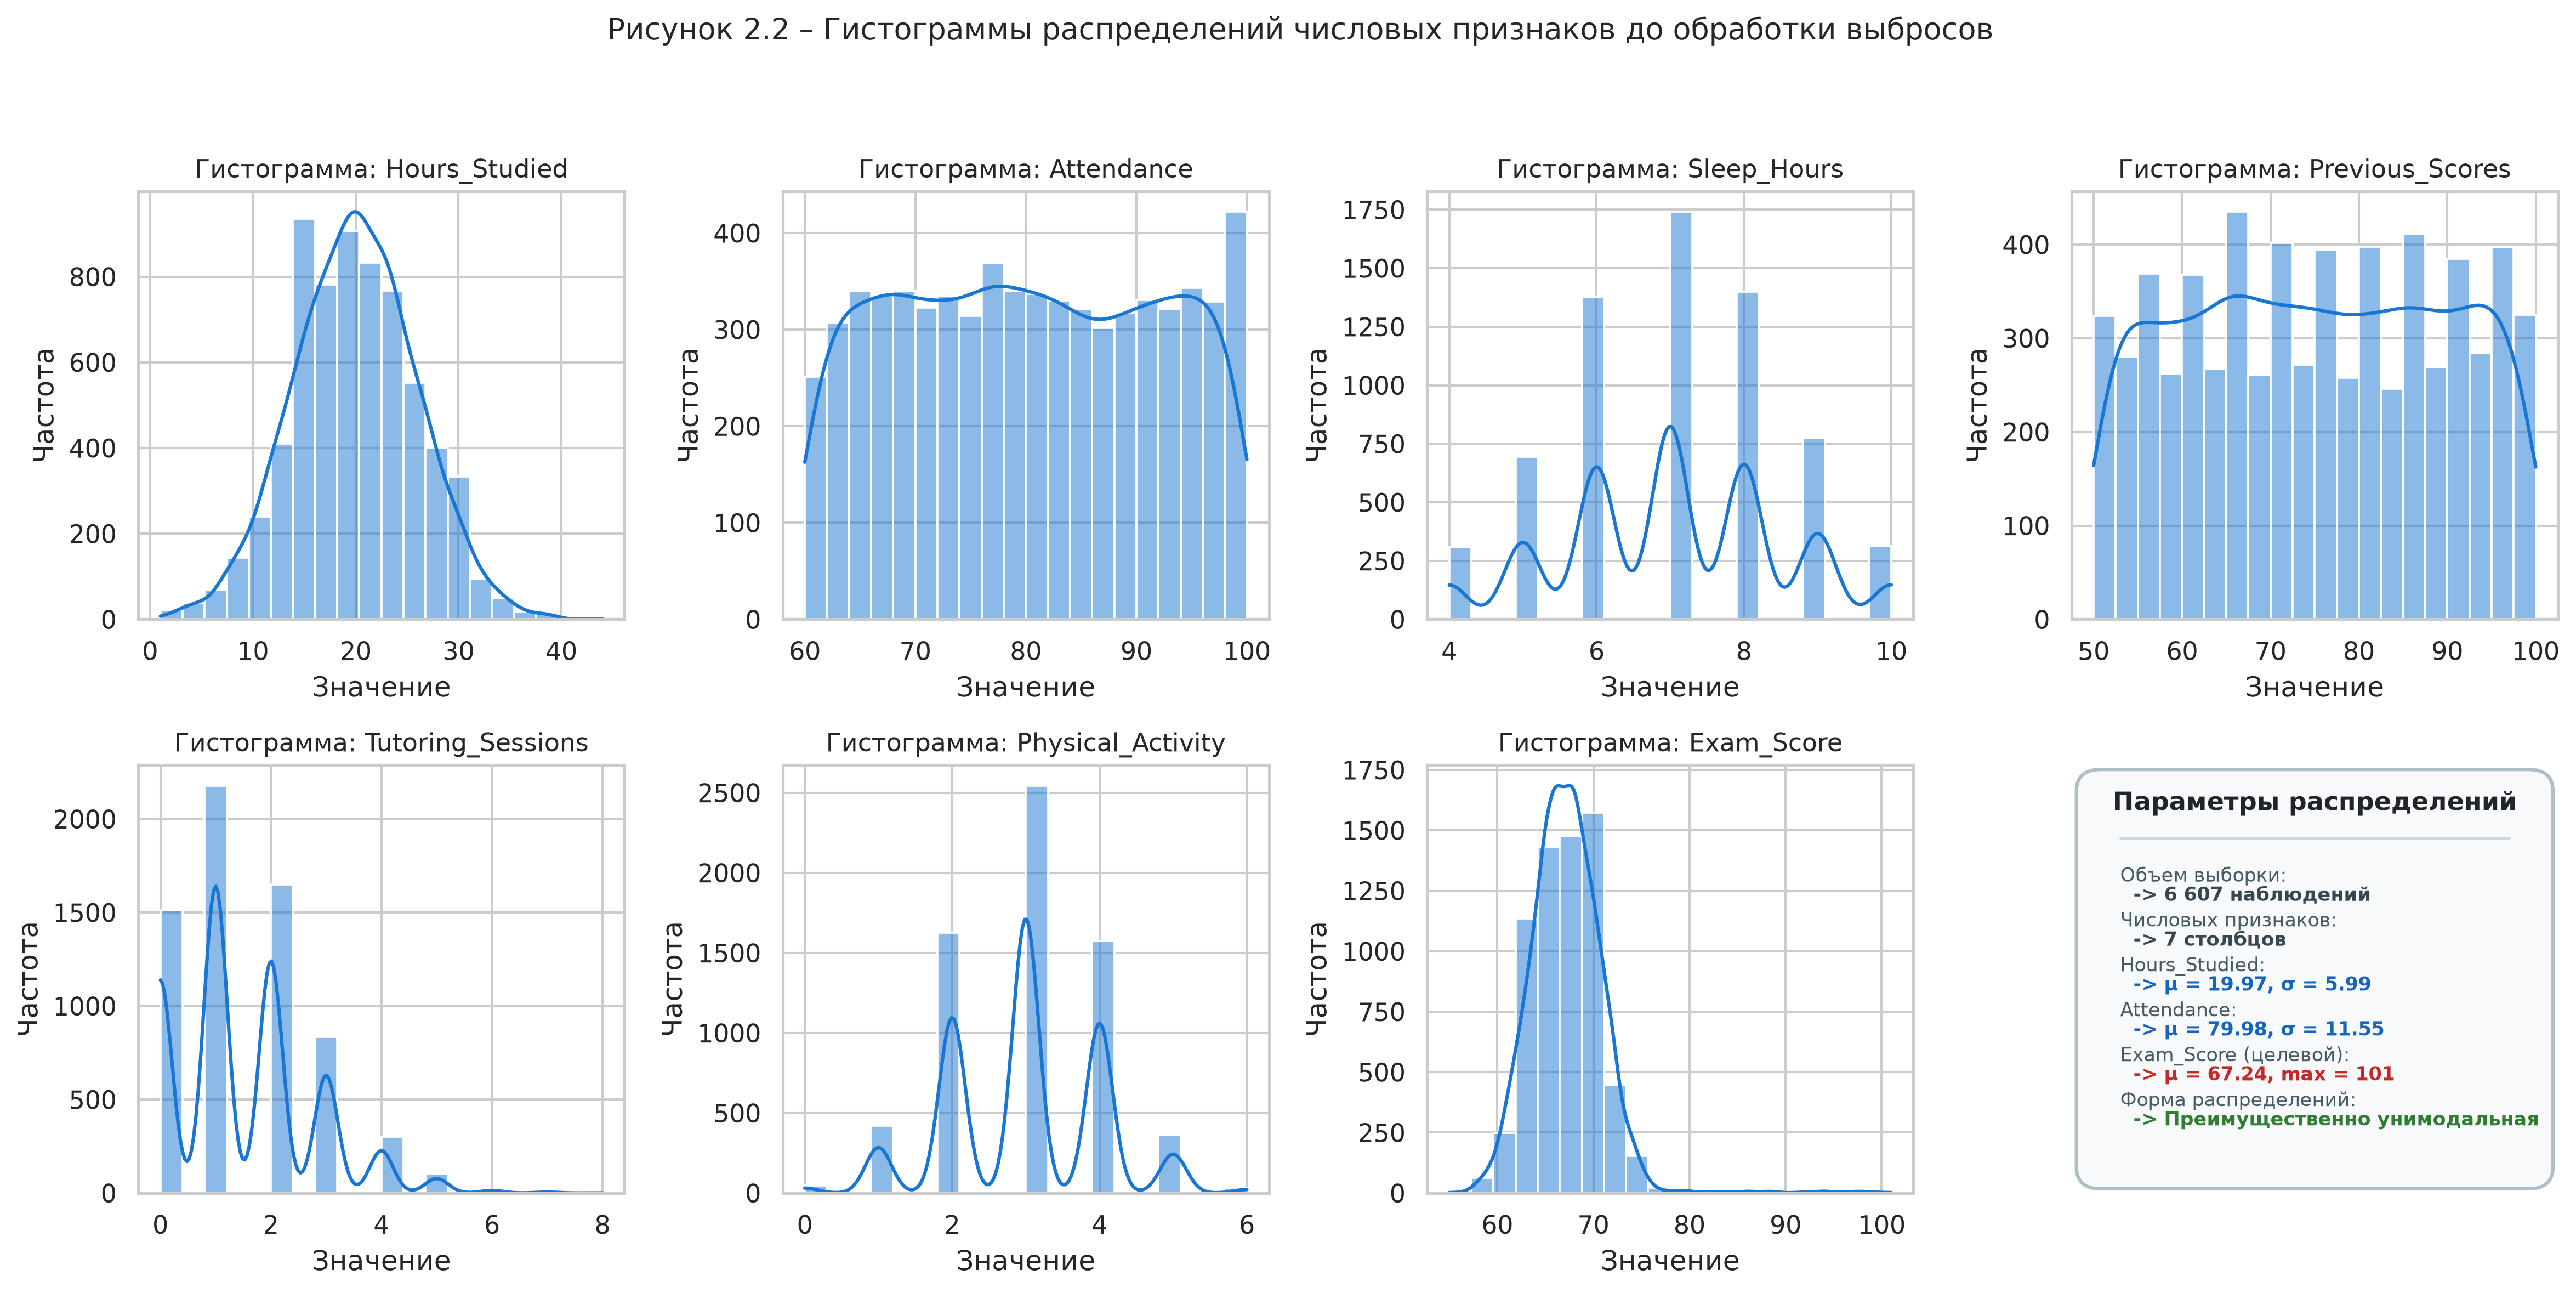

In [3]:
num_cols = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 
            'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, col in enumerate(num_cols):
    r, c = divmod(i, 4)
    sns.histplot(df[col], kde=True, ax=axes[r, c], color='#1976d2', bins=20)
    axes[r, c].set_title(f'Гистограмма: {col}')
    axes[r, c].set_xlabel('Значение')
    axes[r, c].set_ylabel('Частота')
plt.suptitle('Рисунок 2.2 – Гистограммы распределений числовых признаков до обработки выбросов')
plt.tight_layout()
plt.show()


### 2.3. Обнаружение выбросов по методу Тьюки (IQR / BoxPlot)

В соответствии с правилом Тьюки, выбросами считаются точки, выходящие за пределы доверительного интервала:
$$x < Q_1 - 1.5 \cdot IQR \quad \text{или} \quad x > Q_3 + 1.5 \cdot IQR,$$
где $IQR = Q_3 - Q_1$ — межквартильный размах.


Статистика выбросов (IQR):
Hours_Studied       : Q1=16.0, Q3=24.0, IQR= 8.0, Границы=[  4.0,  36.0], Выбросов: 43
Attendance          : Q1=70.0, Q3=90.0, IQR=20.0, Границы=[ 40.0, 120.0], Выбросов: 0
Sleep_Hours         : Q1= 6.0, Q3= 8.0, IQR= 2.0, Границы=[  3.0,  11.0], Выбросов: 0
Previous_Scores     : Q1=63.0, Q3=88.0, IQR=25.0, Границы=[ 25.5, 125.5], Выбросов: 0
Tutoring_Sessions   : Q1= 1.0, Q3= 2.0, IQR= 1.0, Границы=[ -0.5,   3.5], Выбросов: 430
Physical_Activity   : Q1= 2.0, Q3= 4.0, IQR= 2.0, Границы=[ -1.0,   7.0], Выбросов: 0
Exam_Score          : Q1=65.0, Q3=69.0, IQR= 4.0, Границы=[ 59.0,  75.0], Выбросов: 104


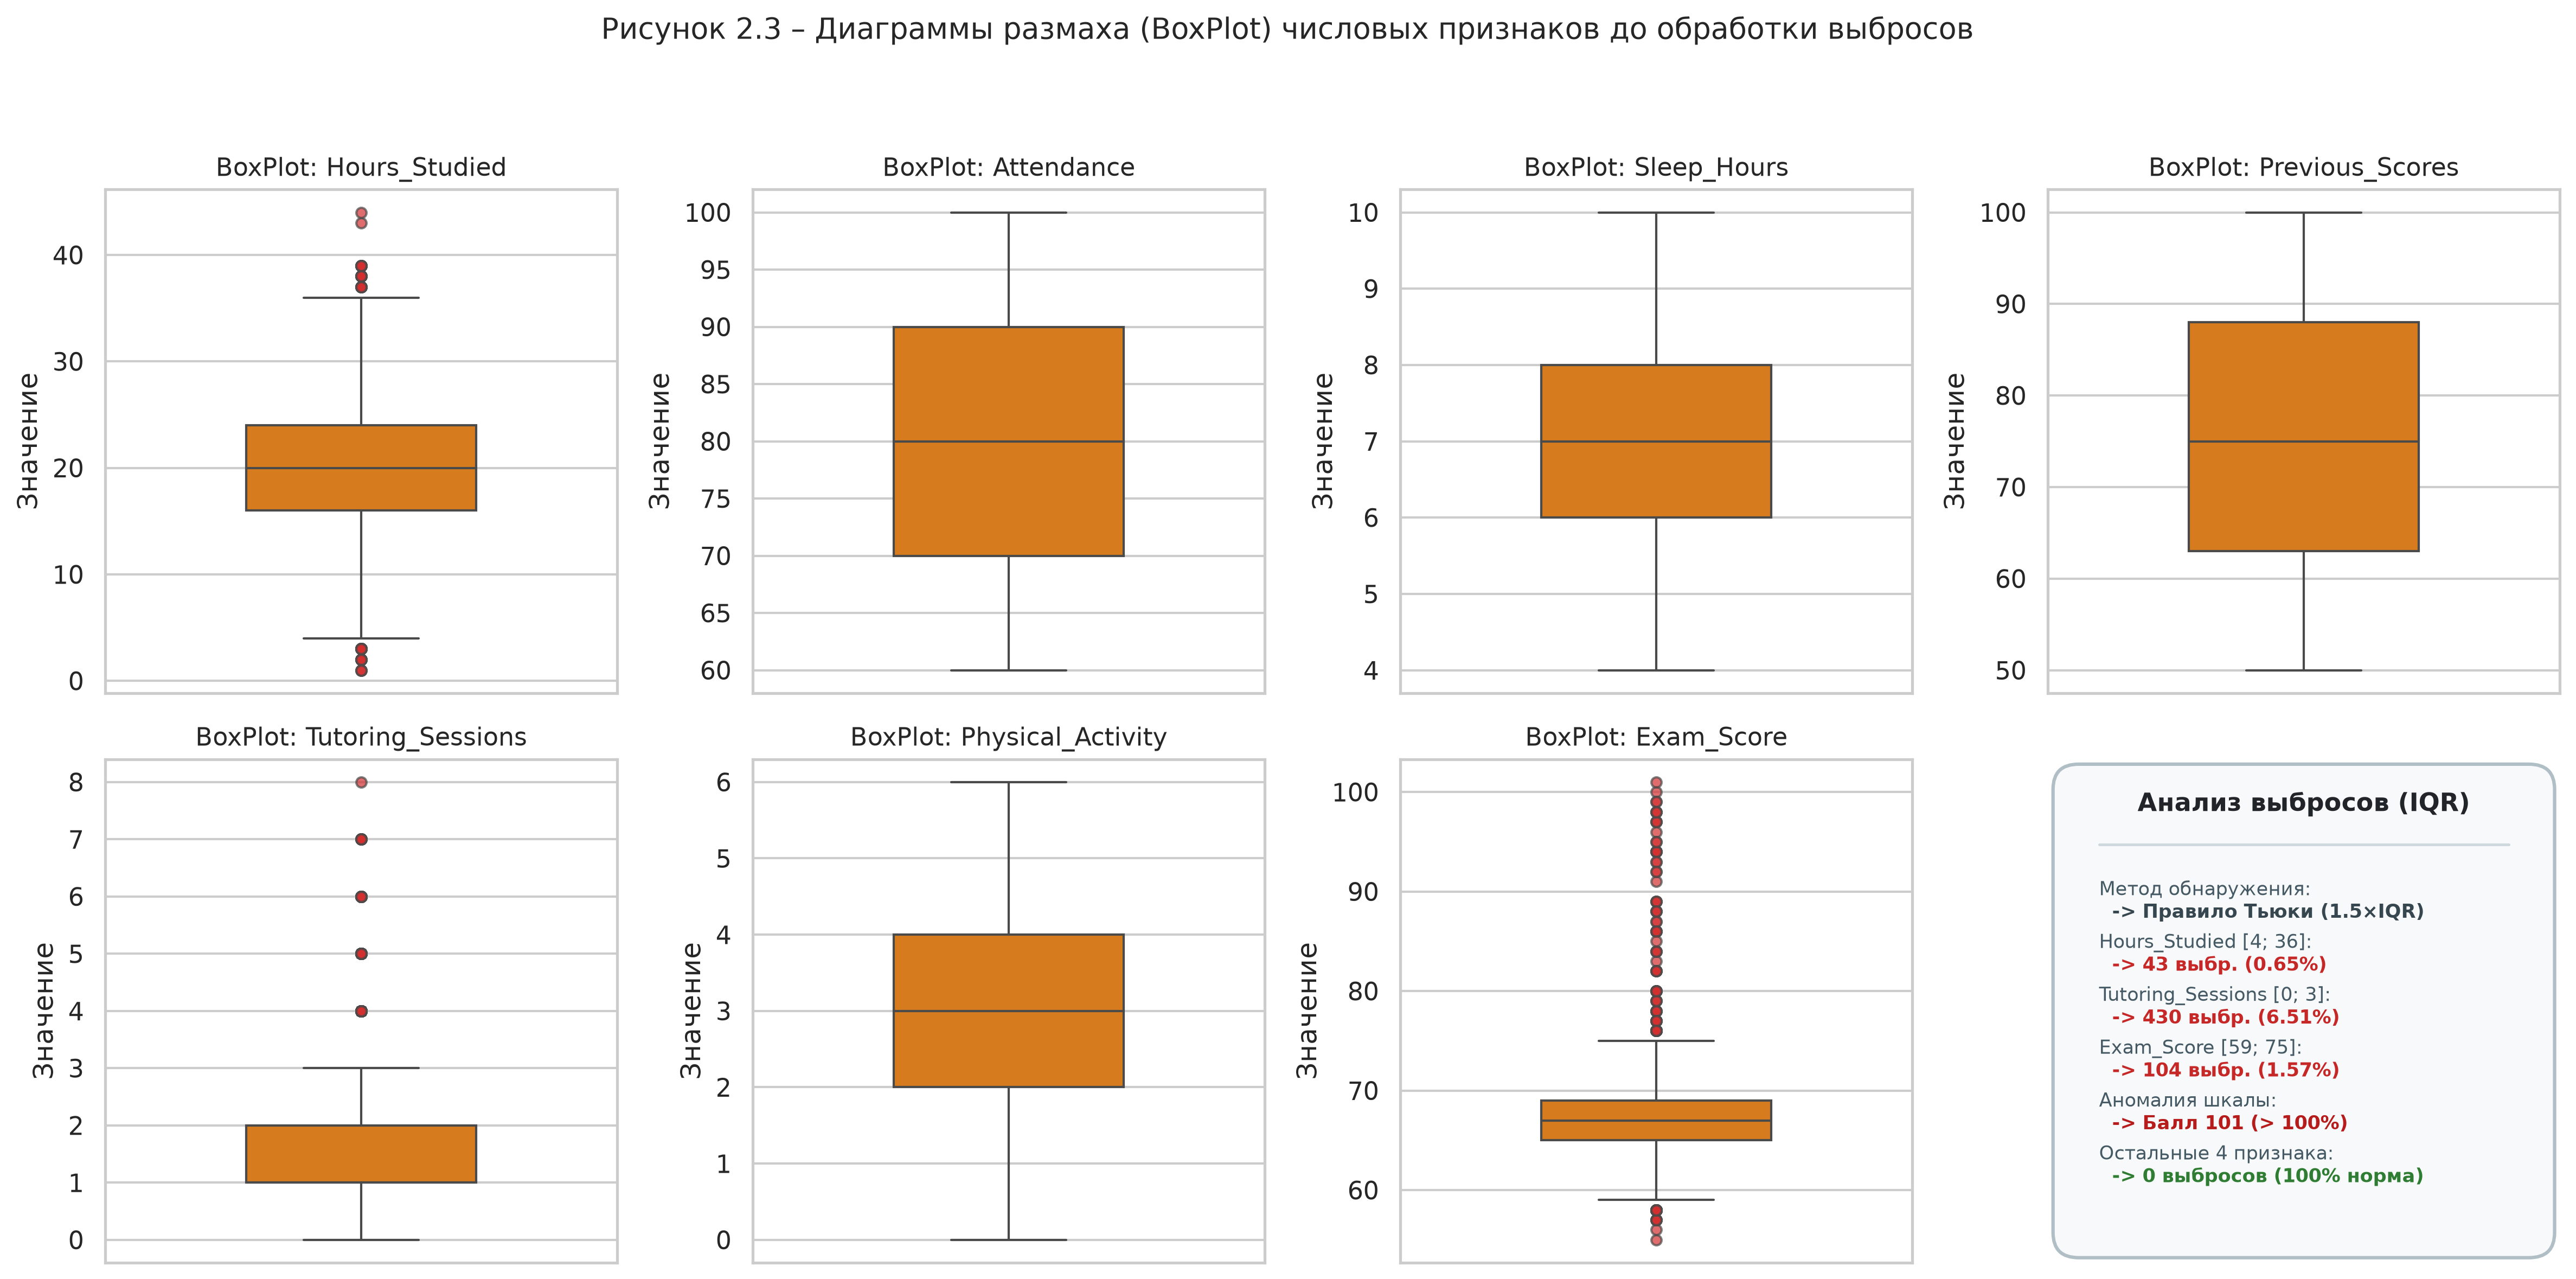

In [4]:
print('Сводная статистика числовых признаков:')
display(df[num_cols].describe().T)

# Расчет границ Тьюки и числа выбросов
print('\nСтатистика выбросов (IQR):')
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    cnt = int(((df[col] < low) | (df[col] > high)).sum())
    print(f'{col:20s}: Q1={q1:4.1f}, Q3={q3:4.1f}, IQR={iqr:4.1f}, Границы=[{low:5.1f}, {high:5.1f}], Выбросов: {cnt}')

# Построение BoxPlot
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, col in enumerate(num_cols):
    r, c = divmod(i, 4)
    sns.boxplot(y=df[col], ax=axes[r, c], color='#f57c00')
    axes[r, c].set_title(f'BoxPlot: {col}')
plt.suptitle('Рисунок 2.3 – Диаграммы размаха (BoxPlot) числовых признаков до обработки выбросов')
plt.tight_layout()
plt.show()


### 2.4. Заполнение пропусков и устранение аномальных значений

1. **Заполнение пропусков:** Все 3 признака с пропусками (`Teacher_Quality`, `Parental_Education_Level`, `Distance_from_Home`) являются категориальными со сравнительно небольшой долей пропусков (~1.0–1.4%). Наиболее корректной математической стратегией является заполнение **модой** (наиболее часто встречающейся категорией), что сохраняет форму распределения.
2. **Устранение выбросов:** Для признаков `Hours_Studied`, `Tutoring_Sessions` и `Exam_Score` применяется метод **винзоризации (clipping)** по границам интервала Тьюки $[Q_1 - 1.5 \cdot IQR, Q_3 + 1.5 \cdot IQR]$. Для дискретного признака `Tutoring_Sessions` верхняя граница 3.5 целочисленно ограничивает допустимый диапазон до $[0, 3]$. Это исключает искажение статистических оценок и сохраняет все 6607 наблюдений выборки.


Пропуски в Teacher_Quality заполнены модой: "Medium"
Пропуски в Parental_Education_Level заполнены модой: "High School"
Пропуски в Distance_from_Home заполнены модой: "Near"
Выбросы успешно ограничены методами винзоризации.
Оставшихся пропусков в датасете: 0


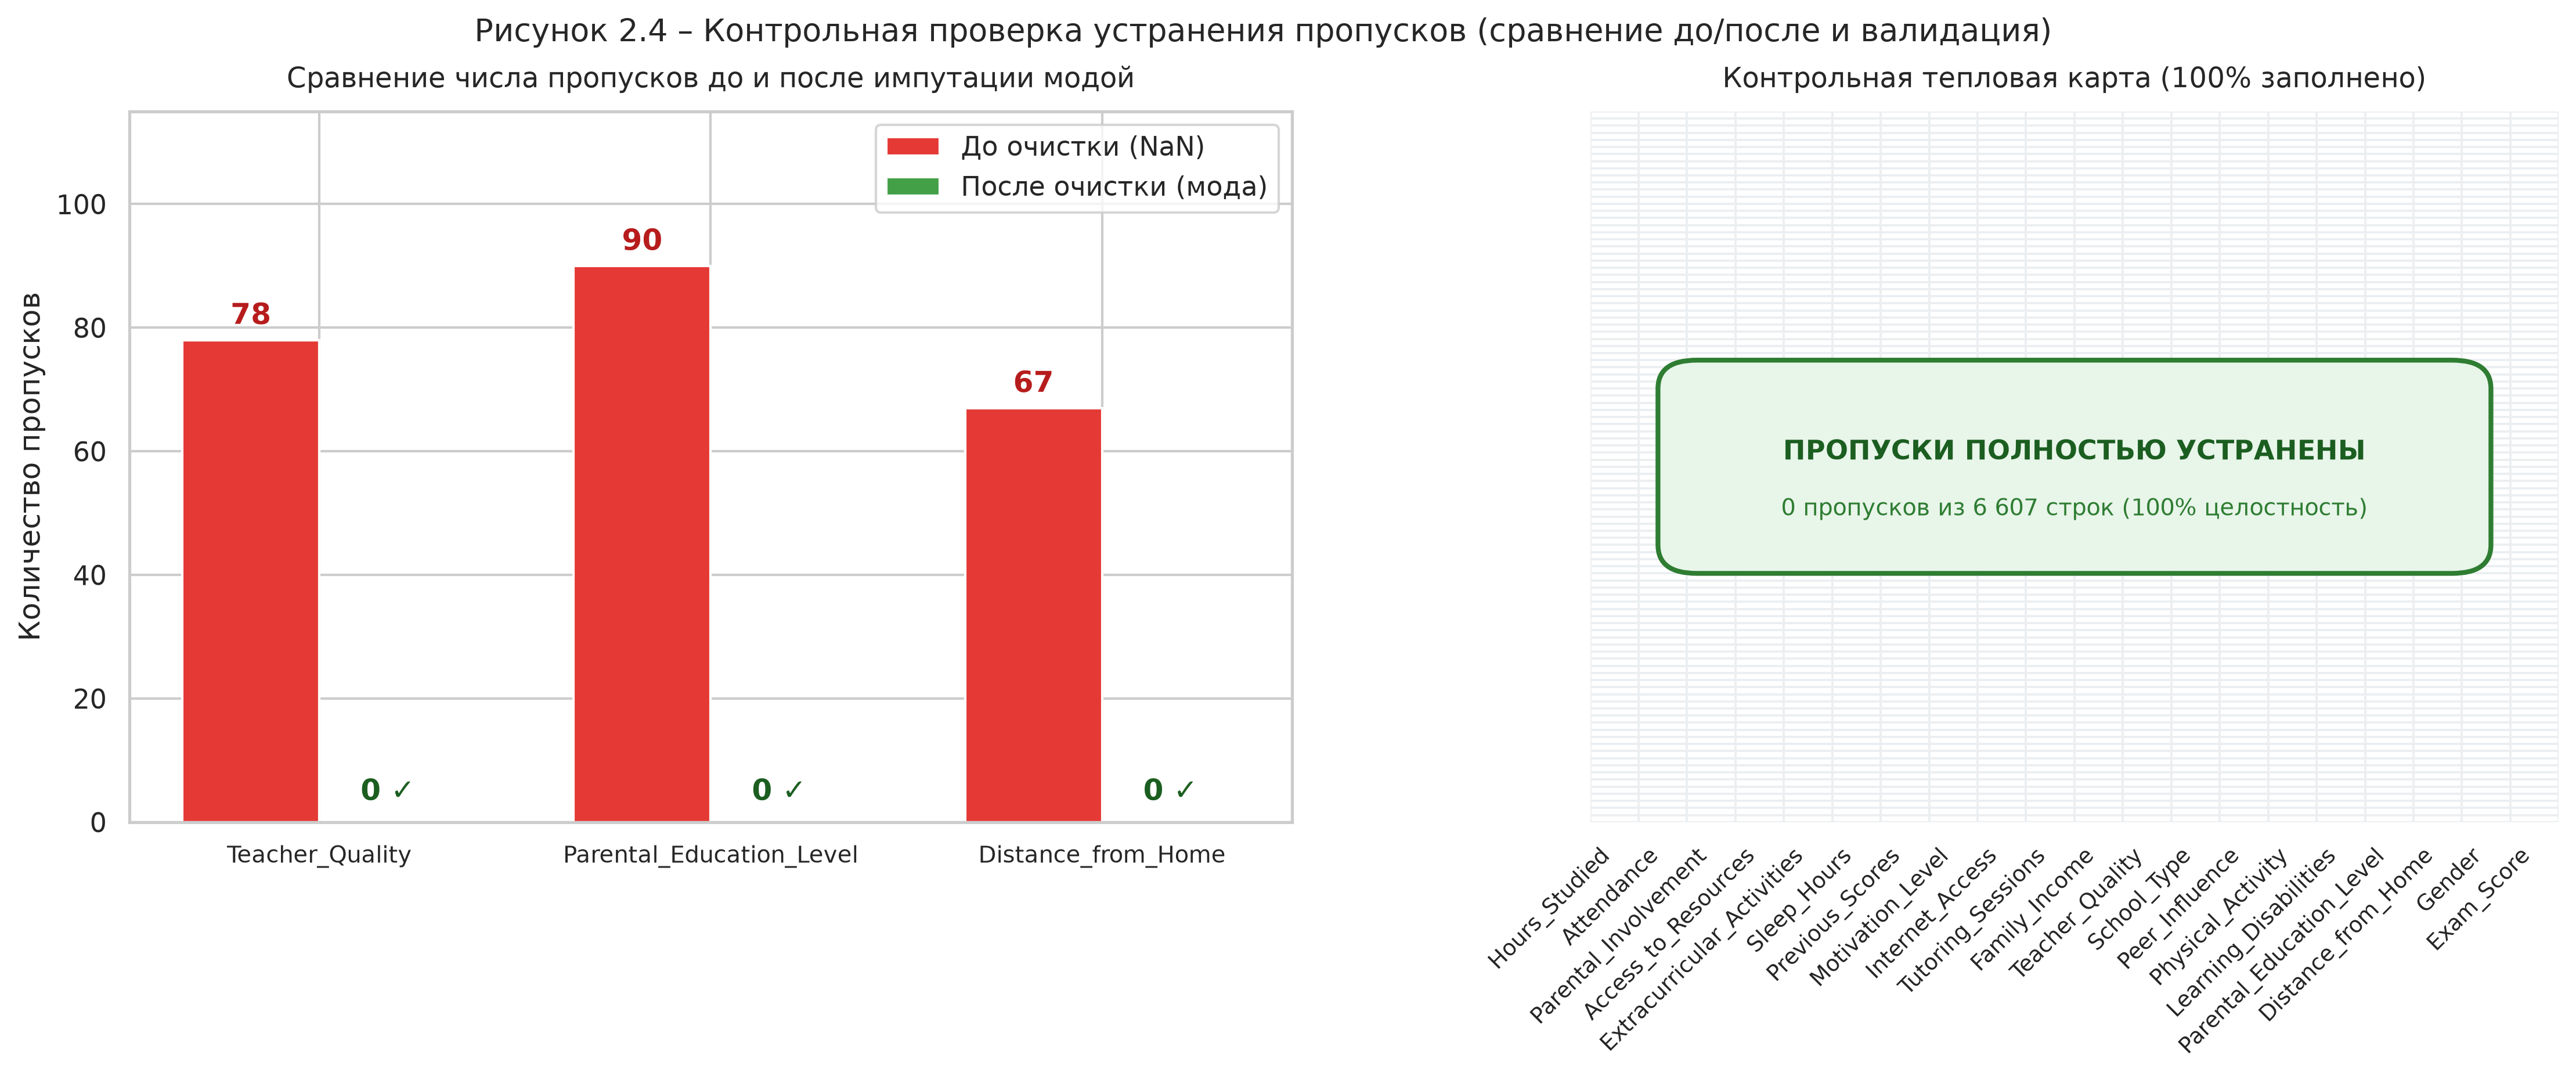

In [5]:
df_clean = df.copy()

# 1. Заполнение пропусков модой
missing_cols = ['Teacher_Quality', 'Parental_Education_Level', 'Distance_from_Home']
for col in missing_cols:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)
    print(f'Пропуски в {col} заполнены модой: "{mode_val}"')

# 2. Винзоризация (Clipping) выбросов
df_clean['Hours_Studied'] = df_clean['Hours_Studied'].clip(lower=4, upper=36)
df_clean['Tutoring_Sessions'] = df_clean['Tutoring_Sessions'].clip(lower=0, upper=3)
df_clean['Exam_Score'] = df_clean['Exam_Score'].clip(lower=59, upper=75)
print('Выбросы успешно ограничены методами винзоризации.')
print(f'Оставшихся пропусков в датасете: {df_clean.isnull().sum().sum()}')


### 2.5. Контрольная графическая проверка отсутствия пропусков и аномалий

Проверяем результаты очистки при помощи контрольных графиков: диаграмм размаха BoxPlot (все точки строго внутри доверительных усов) и контрольных гистограмм распределений после устранения выбросов.


Графическая проверка BoxPlot подтверждает 100% отсутствие выбросов.


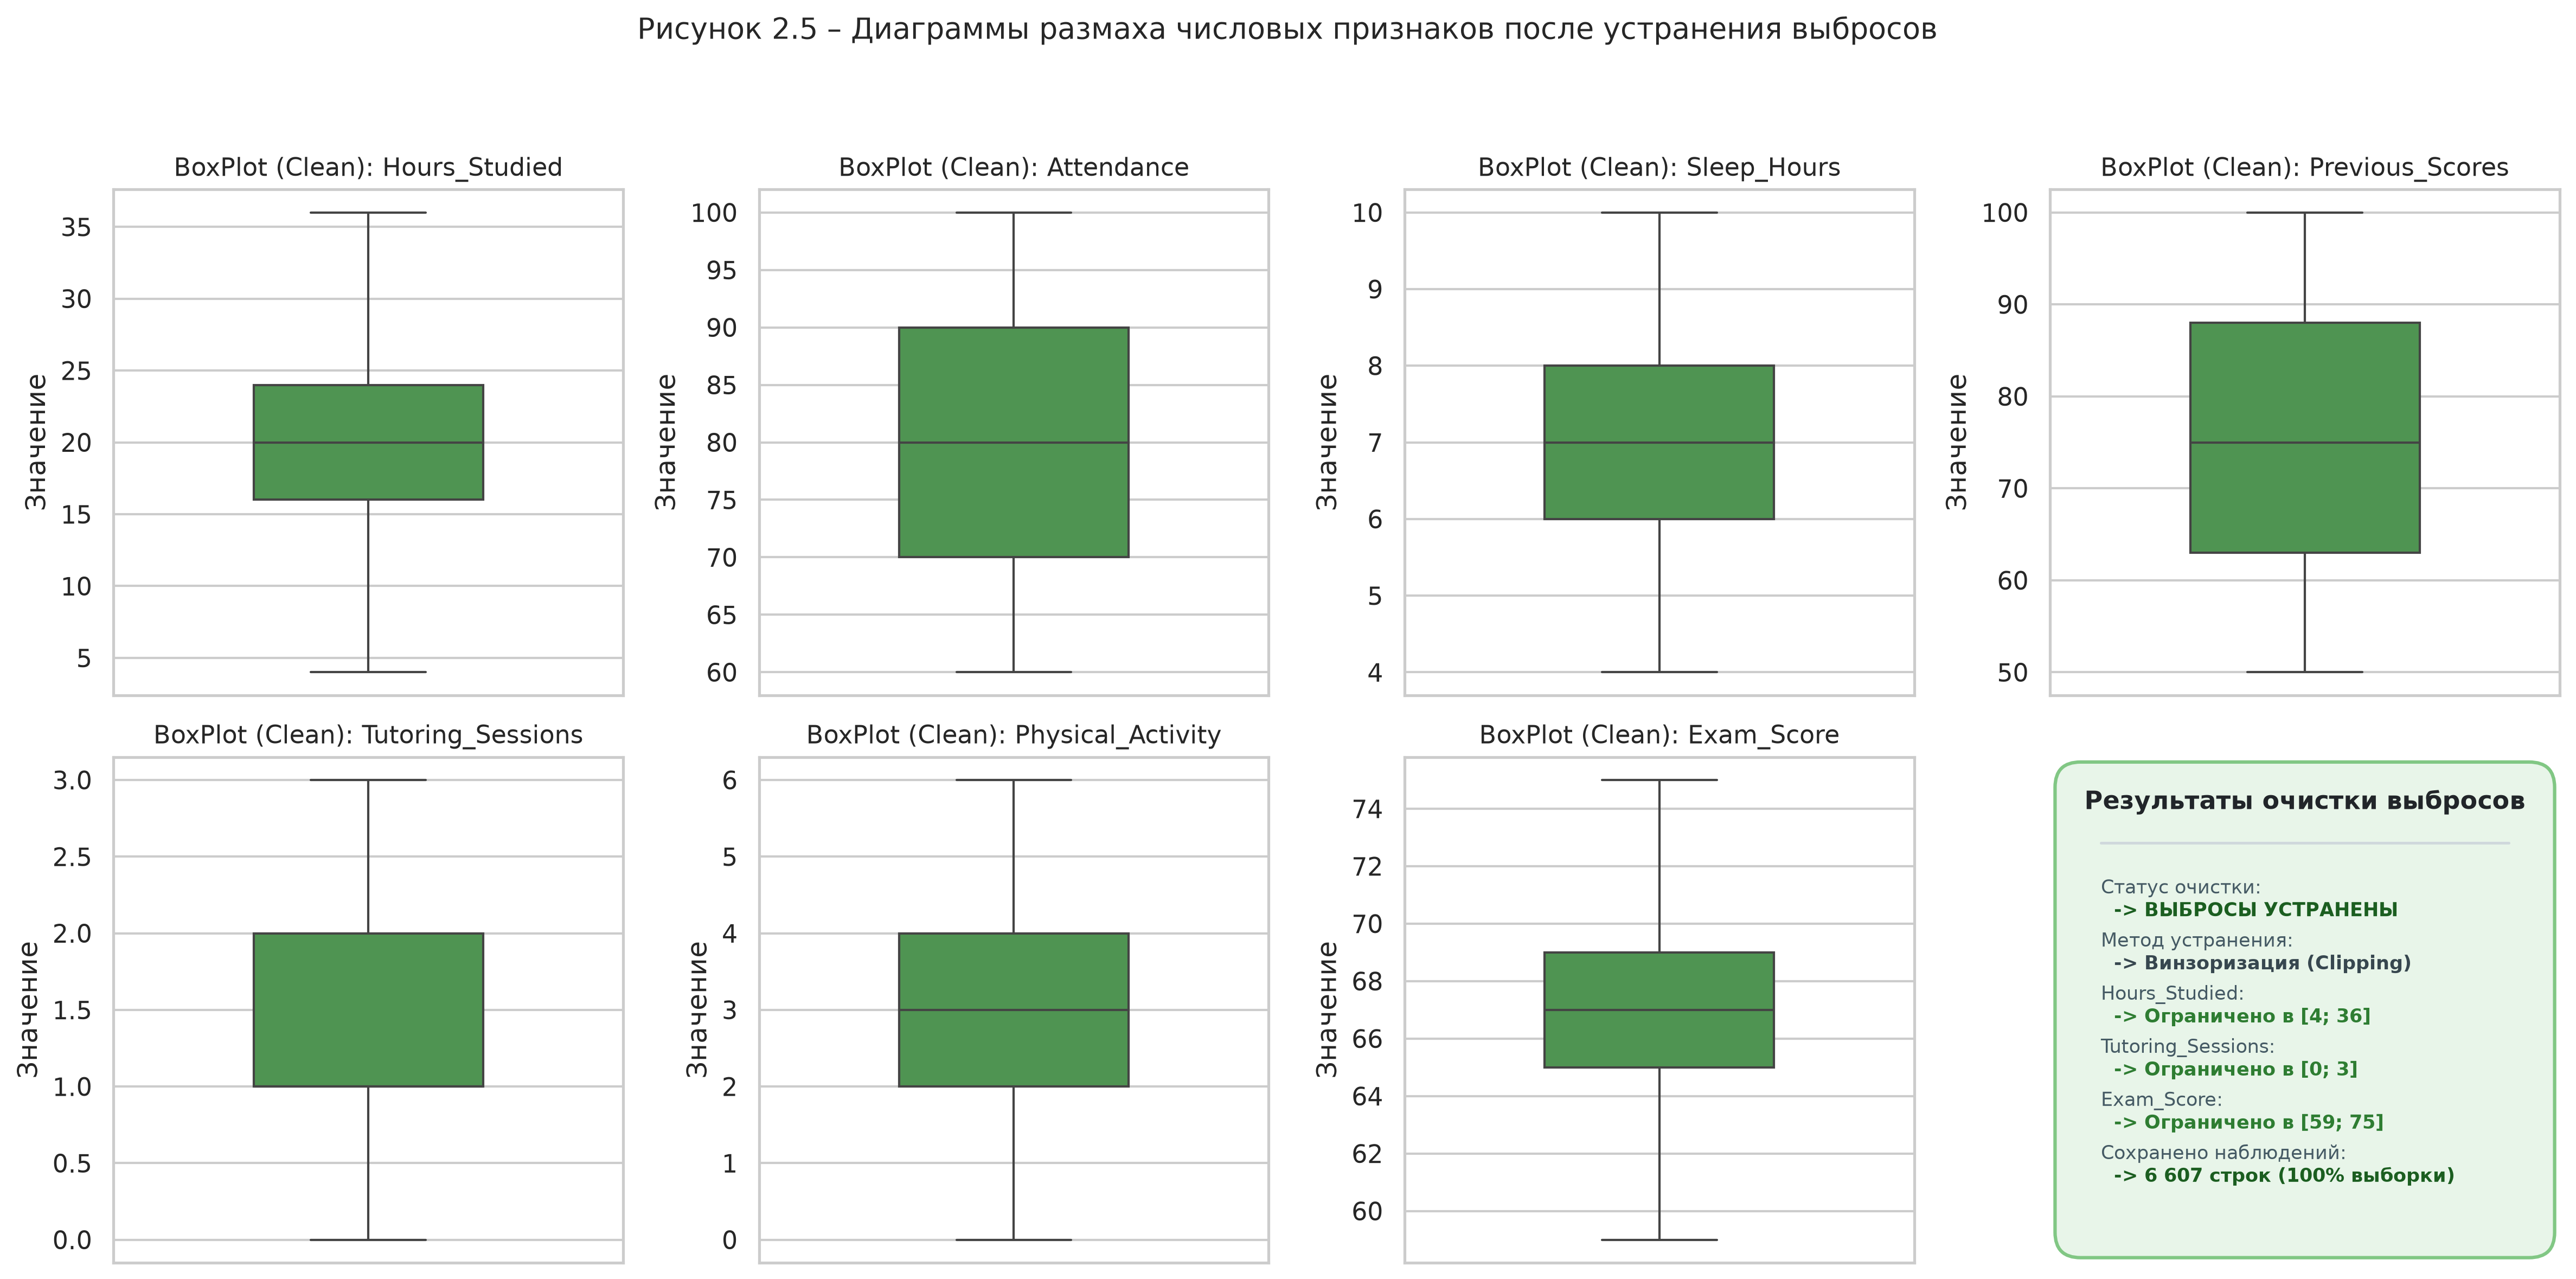

In [6]:
# Графическая проверка BoxPlot после очистки
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, col in enumerate(num_cols):
    r, c = divmod(i, 4)
    sns.boxplot(y=df_clean[col], ax=axes[r, c], color='#43a047', width=0.45)
    axes[r, c].set_title(f'BoxPlot (Clean): {col}')
plt.suptitle('Рисунок 2.5 – Диаграммы размаха числовых признаков после устранения выбросов')
plt.tight_layout()
plt.show()


Кривые распределений сглажены, аномальные выбросы за пределами шкалы устранены.


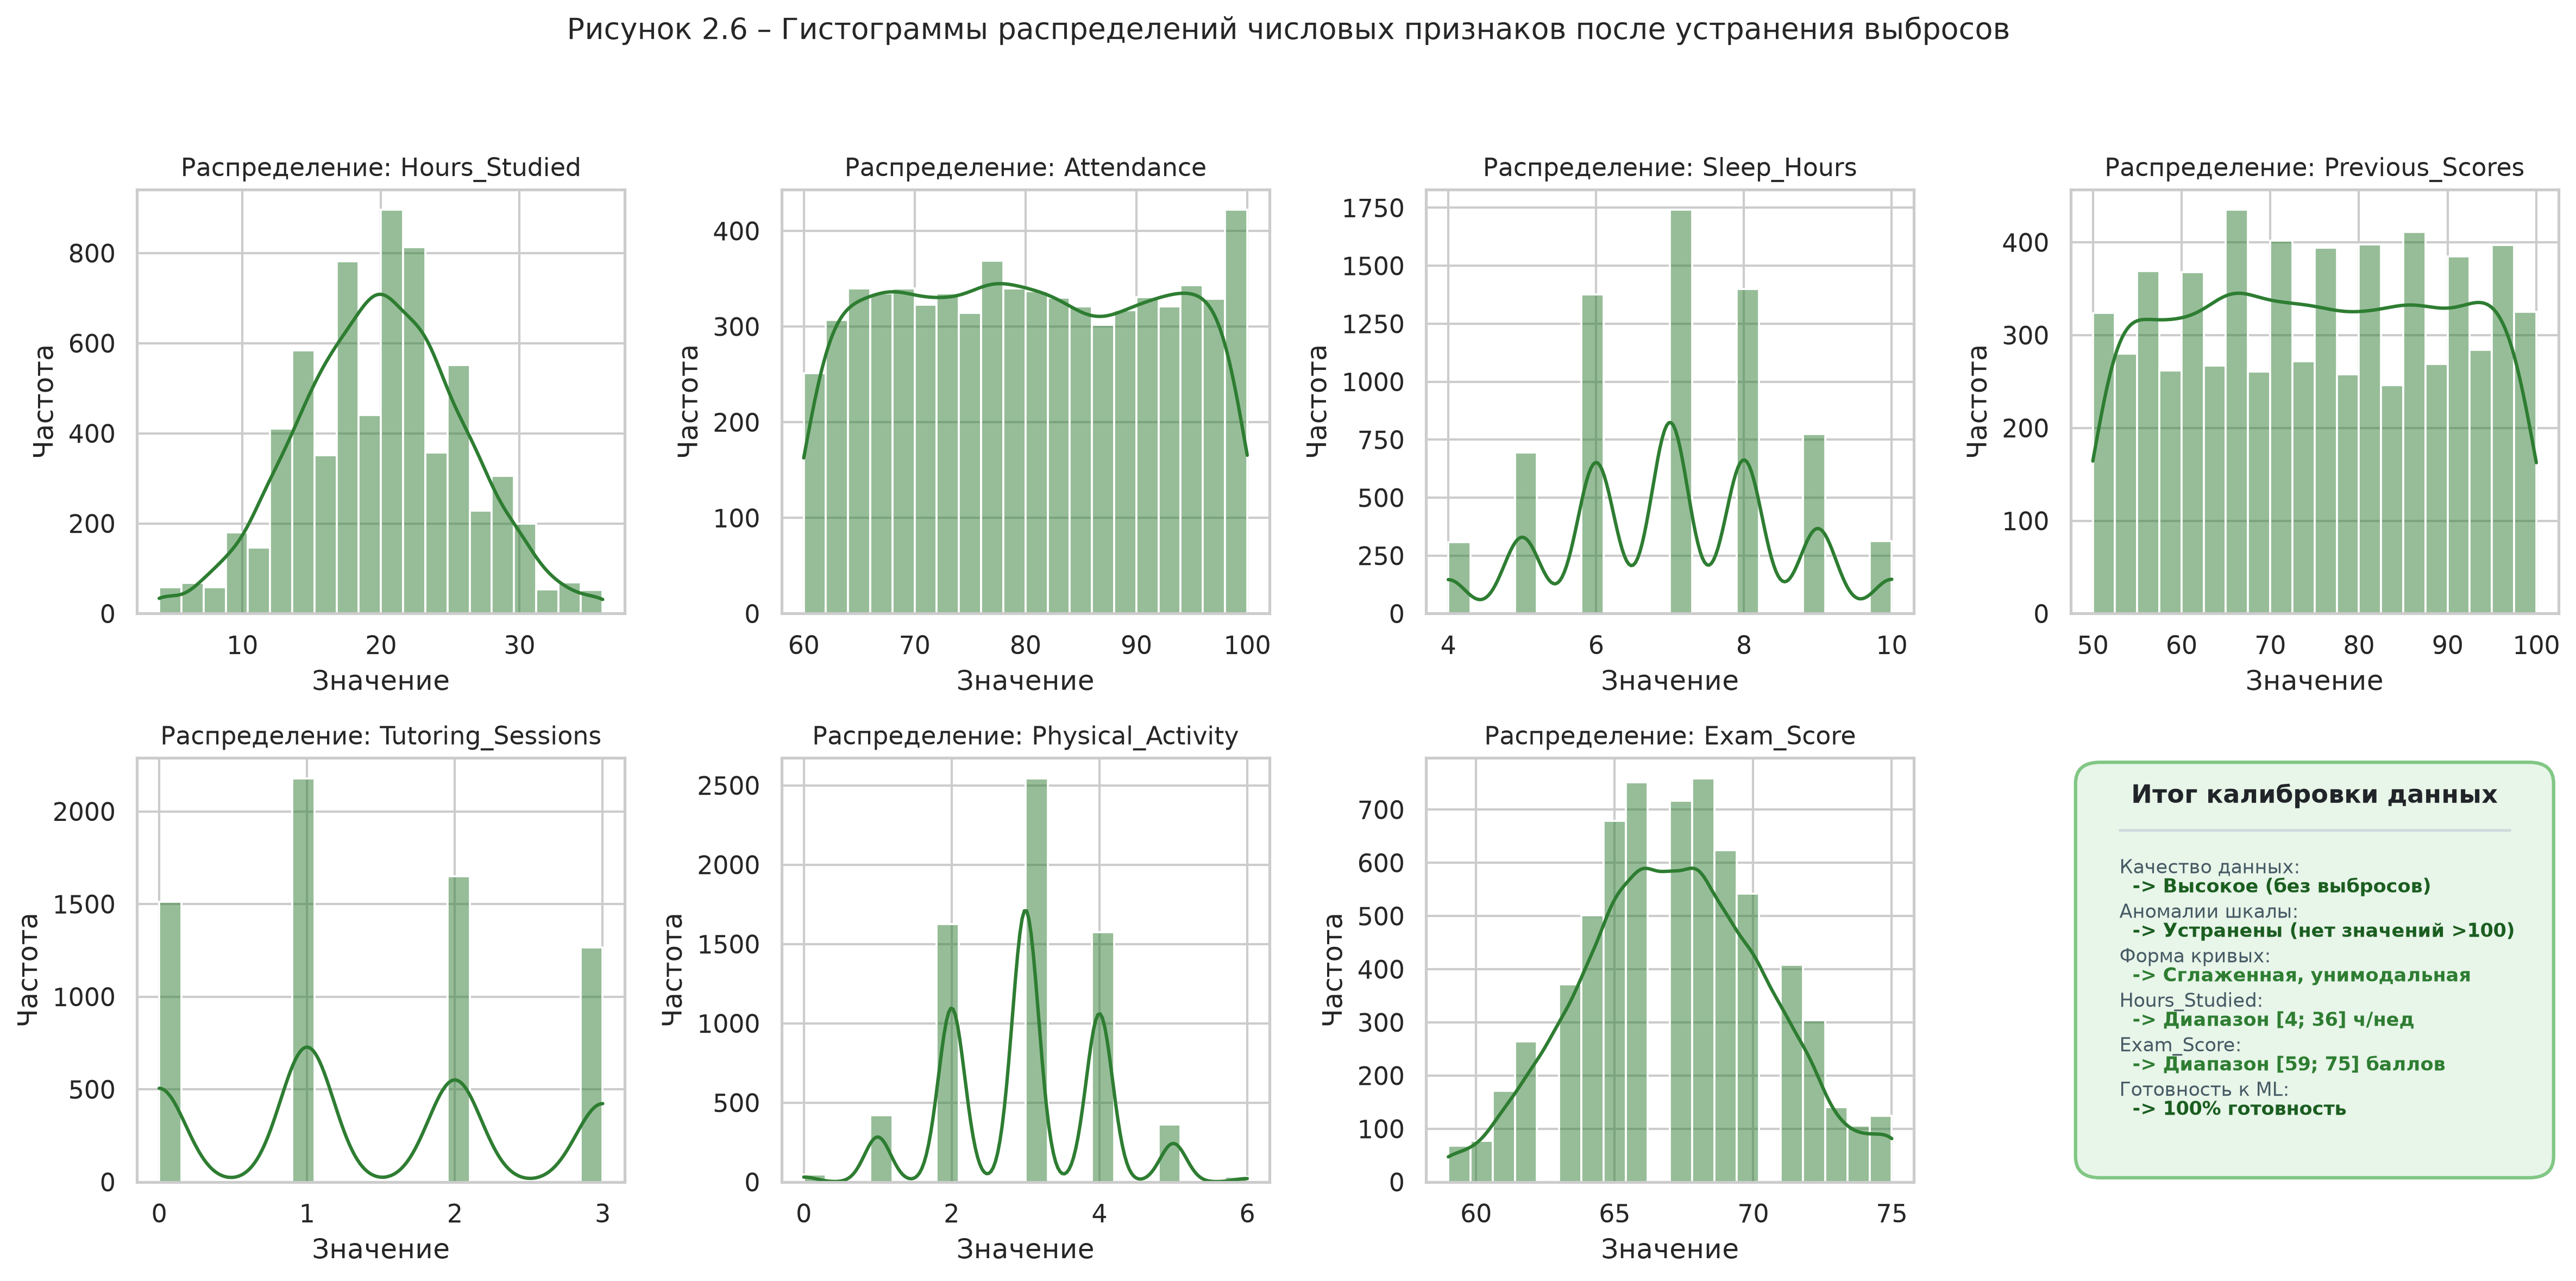

In [7]:
# Контрольные гистограммы распределений после винзоризации
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, col in enumerate(num_cols):
    r, c = divmod(i, 4)
    sns.histplot(df_clean[col], kde=True, ax=axes[r, c], color='#2e7d32', bins=20)
    axes[r, c].set_title(f'Распределение: {col}')
plt.suptitle('Рисунок 2.6 – Гистограммы распределений числовых признаков после устранения выбросов')
plt.tight_layout()
plt.show()


## 3. Генерация новых признаков и кодирование категориальных данных

### 3.1. Конструирование новых признаков (Feature Engineering)
Создаем три новых содержательных признака, обогащающих модель дополнительной физической логикой предметной области:
1. **`Study_to_Sleep_Ratio`**: Отношение времени учебы ко сну:
   $$\text{Study\_to\_Sleep\_Ratio} = \frac{\text{Hours\_Studied}}{\text{Sleep\_Hours}}$$
   Характеризует баланс нагрузки и биологического отдыха студента.
2. **`Academic_Effort_Index`**: Интегральный индекс академических усилий:
   $$\text{Academic\_Effort\_Index} = (\text{Hours\_Studied} + 1.5 \cdot \text{Tutoring\_Sessions}) \cdot \frac{\text{Attendance}}{100}$$
   Комплексно учитывает аудиторную посещаемость, самостоятельную подготовку и интенсивность занятий с репетитором.
3. **`Score_Growth`**: Прирост успеваемости относительно прошлых срезов:
   $$\text{Score\_Growth} = \text{Exam\_Score} - \text{Previous\_Scores}$$
   Отражает академическую динамику и личный прогресс обучающегося.


Статистика сгенерированных признаков:
       Study_to_Sleep_Ratio  Academic_Effort_Index  Score_Growth
count           6607.000000            6607.000000   6607.000000
mean               2.980098              17.652717     -7.943393
std                1.144206               5.550009     14.132118
min                0.400000               2.400000    -39.000000
50%                2.860000              17.390000     -8.000000
max                9.000000              38.220000     23.000000


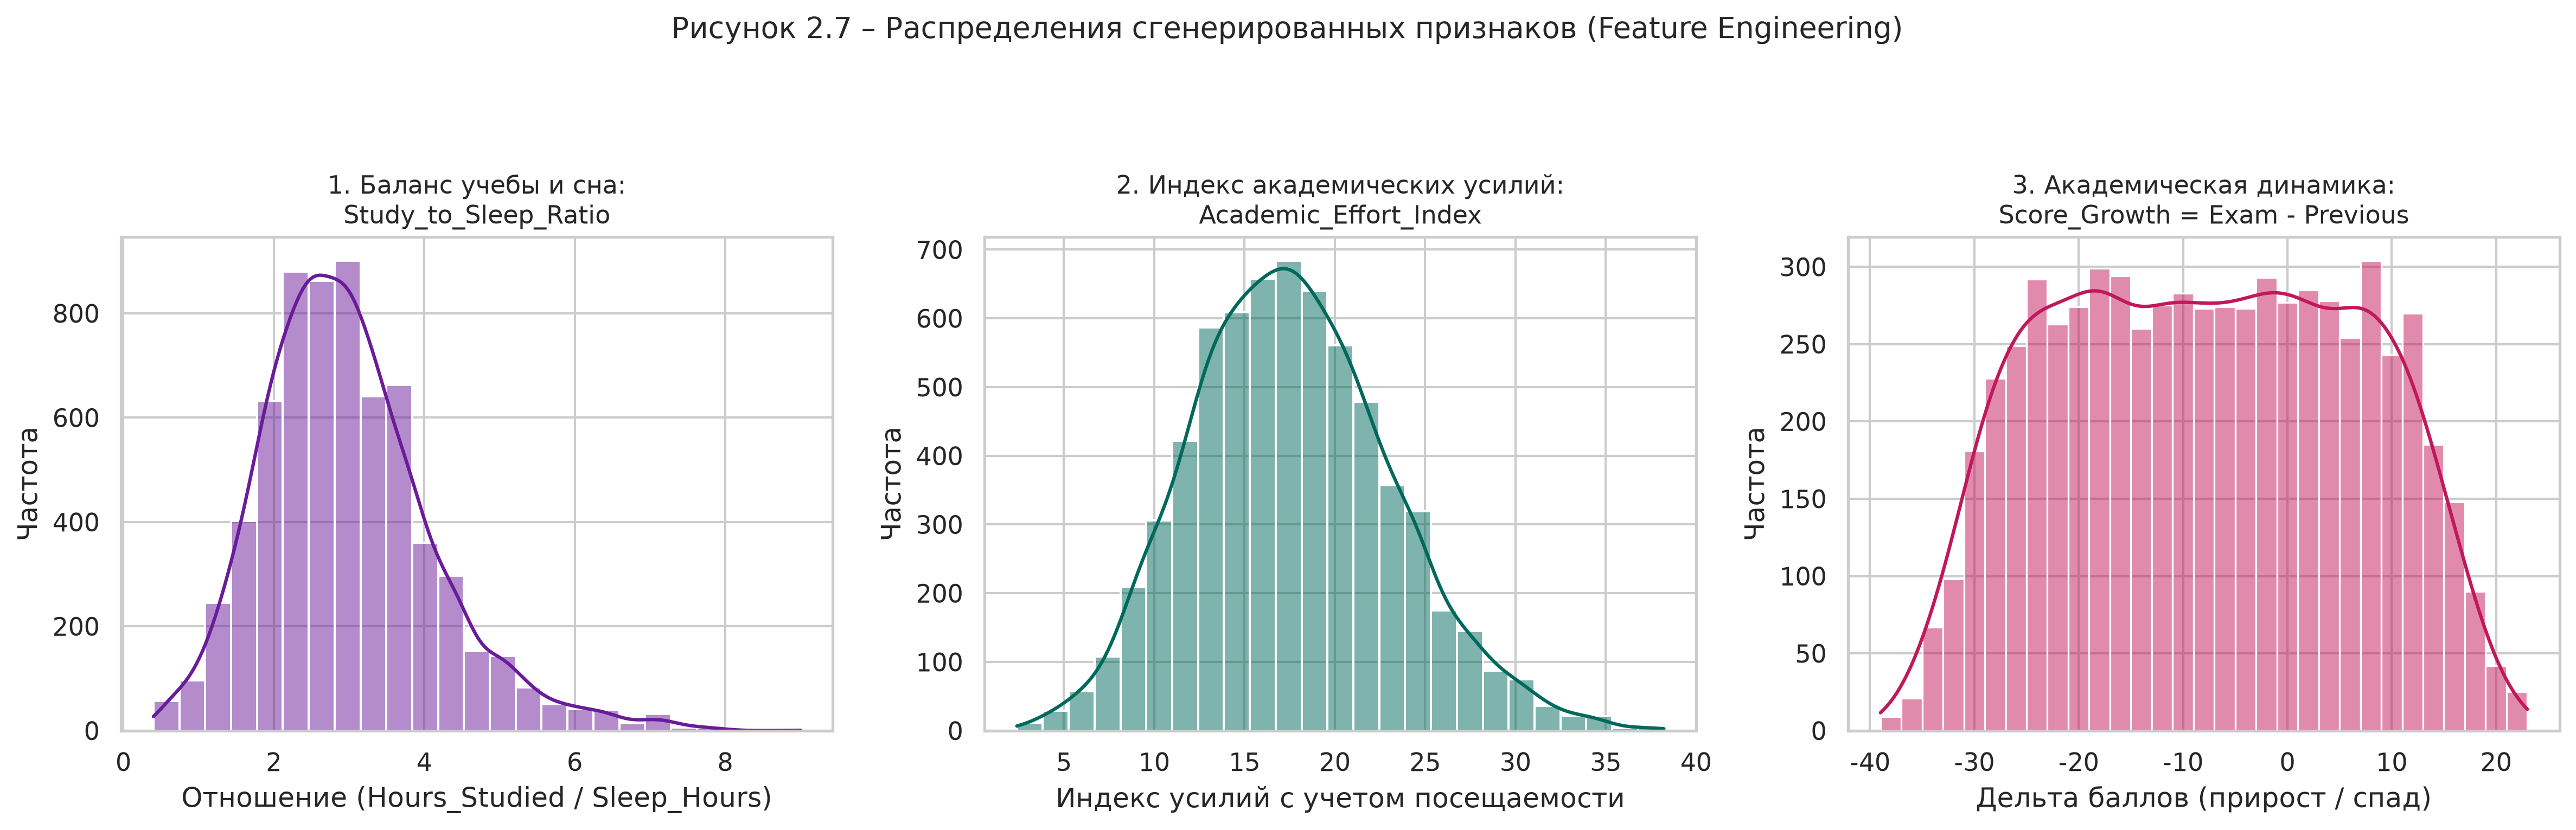

In [8]:
# Генерация новых признаков
df_clean['Study_to_Sleep_Ratio'] = np.round(df_clean['Hours_Studied'] / df_clean['Sleep_Hours'], 2)
df_clean['Academic_Effort_Index'] = np.round((df_clean['Hours_Studied'] + df_clean['Tutoring_Sessions'] * 1.5) * (df_clean['Attendance'] / 100.0), 2)
df_clean['Score_Growth'] = np.round(df_clean['Exam_Score'] - df_clean['Previous_Scores'], 1)

new_cols = ['Study_to_Sleep_Ratio', 'Academic_Effort_Index', 'Score_Growth']
print('Статистика сгенерированных признаков:')
display(df_clean[new_cols].describe())


### 3.2. Кодирование категориальных признаков

1. **Бинаризация (Binary Encoding):** Применяется к дихотомическим признакам с двумя возможными значениями. Значения отображаются в $\{0, 1\}$, что не раздувает размерность матрицы признаков:
   - `Gender`: Male $\rightarrow 1$, Female $\rightarrow 0$;
   - `Extracurricular_Activities`: Yes $\rightarrow 1$, No $\rightarrow 0$;
   - `Internet_Access`: Yes $\rightarrow 1$, No $\rightarrow 0$;
   - `Learning_Disabilities`: Yes $\rightarrow 1$, No $\rightarrow 0$;
   - `School_Type`: Public $\rightarrow 1$, Private $\rightarrow 0$.

2. **One-Hot Encoding (OHE):** Применяется для качественных категорий с 3 и более уровнями. Каждое значение преобразуется в отдельный двоичный столбец. Для предотвращения мультиколлинеарности (dummy variable trap) используется аргумент `drop_first=True`.


In [9]:
# 1. Бинаризация бинарных признаков
binary_maps = {
    'Gender': {'Male': 1, 'Female': 0},
    'Extracurricular_Activities': {'Yes': 1, 'No': 0},
    'Internet_Access': {'Yes': 1, 'No': 0},
    'Learning_Disabilities': {'Yes': 1, 'No': 0},
    'School_Type': {'Public': 1, 'Private': 0}
}
for b_col, b_map in binary_maps.items():
    df_clean[b_col] = df_clean[b_col].map(b_map)
    print(f'Бинаризация {b_col}: успешно ({b_map})')

# 2. One-Hot Encoding для многоклассовых категорий
ohe_cols = [
    'Parental_Involvement', 'Access_to_Resources', 'Motivation_Level',
    'Family_Income', 'Teacher_Quality', 'Peer_Influence',
    'Parental_Education_Level', 'Distance_from_Home'
]
df_encoded = pd.get_dummies(df_clean, columns=ohe_cols, drop_first=True, dtype=int)
print(f'\nРазмерность до OHE: {df_clean.shape[1]} признаков')
print(f'Размерность после OHE: {df_encoded.shape[1]} признаков')
df_encoded.head(3)


Бинаризация Gender: успешно ({'Male': 1, 'Female': 0})
Бинаризация Extracurricular_Activities: успешно ({'Yes': 1, 'No': 0})
Бинаризация Internet_Access: успешно ({'Yes': 1, 'No': 0})
Бинаризация Learning_Disabilities: успешно ({'Yes': 1, 'No': 0})
Бинаризация School_Type: успешно ({'Public': 1, 'Private': 0})

Размерность до OHE: 23 признаков
Размерность после OHE: 31 признаков


## 4. Стандартизация и нормализация данных

Большинство алгоритмов машинного обучения (линейная и логистическая регрессия, KNN, SVM, нейросети, PCA) чувствительны к масштабу признаков. В работе реализованы оба базовых метода масштабирования:

1. **Стандартизация (`StandardScaler`)** преобразует признак к распределению с нулевым математическим ожиданием и единичной дисперсией:
   $$z = \frac{x - \mu}{\sigma}, \quad \mu = 0, \; \sigma = 1$$
2. **Нормализация (`MinMaxScaler`)** выполняет линейное сжатие значений в фиксированный отрезок $[0, 1]$:
   $$x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$


Сравнение параметров Hours_Studied:
Исходный : mean=19.92, std=5.84, min=4, max=36
Standard : mean=0.00, std=1.00, min=-2.73, max=2.75
MinMax   : mean=0.50, std=0.18, min=0.00, max=1.00


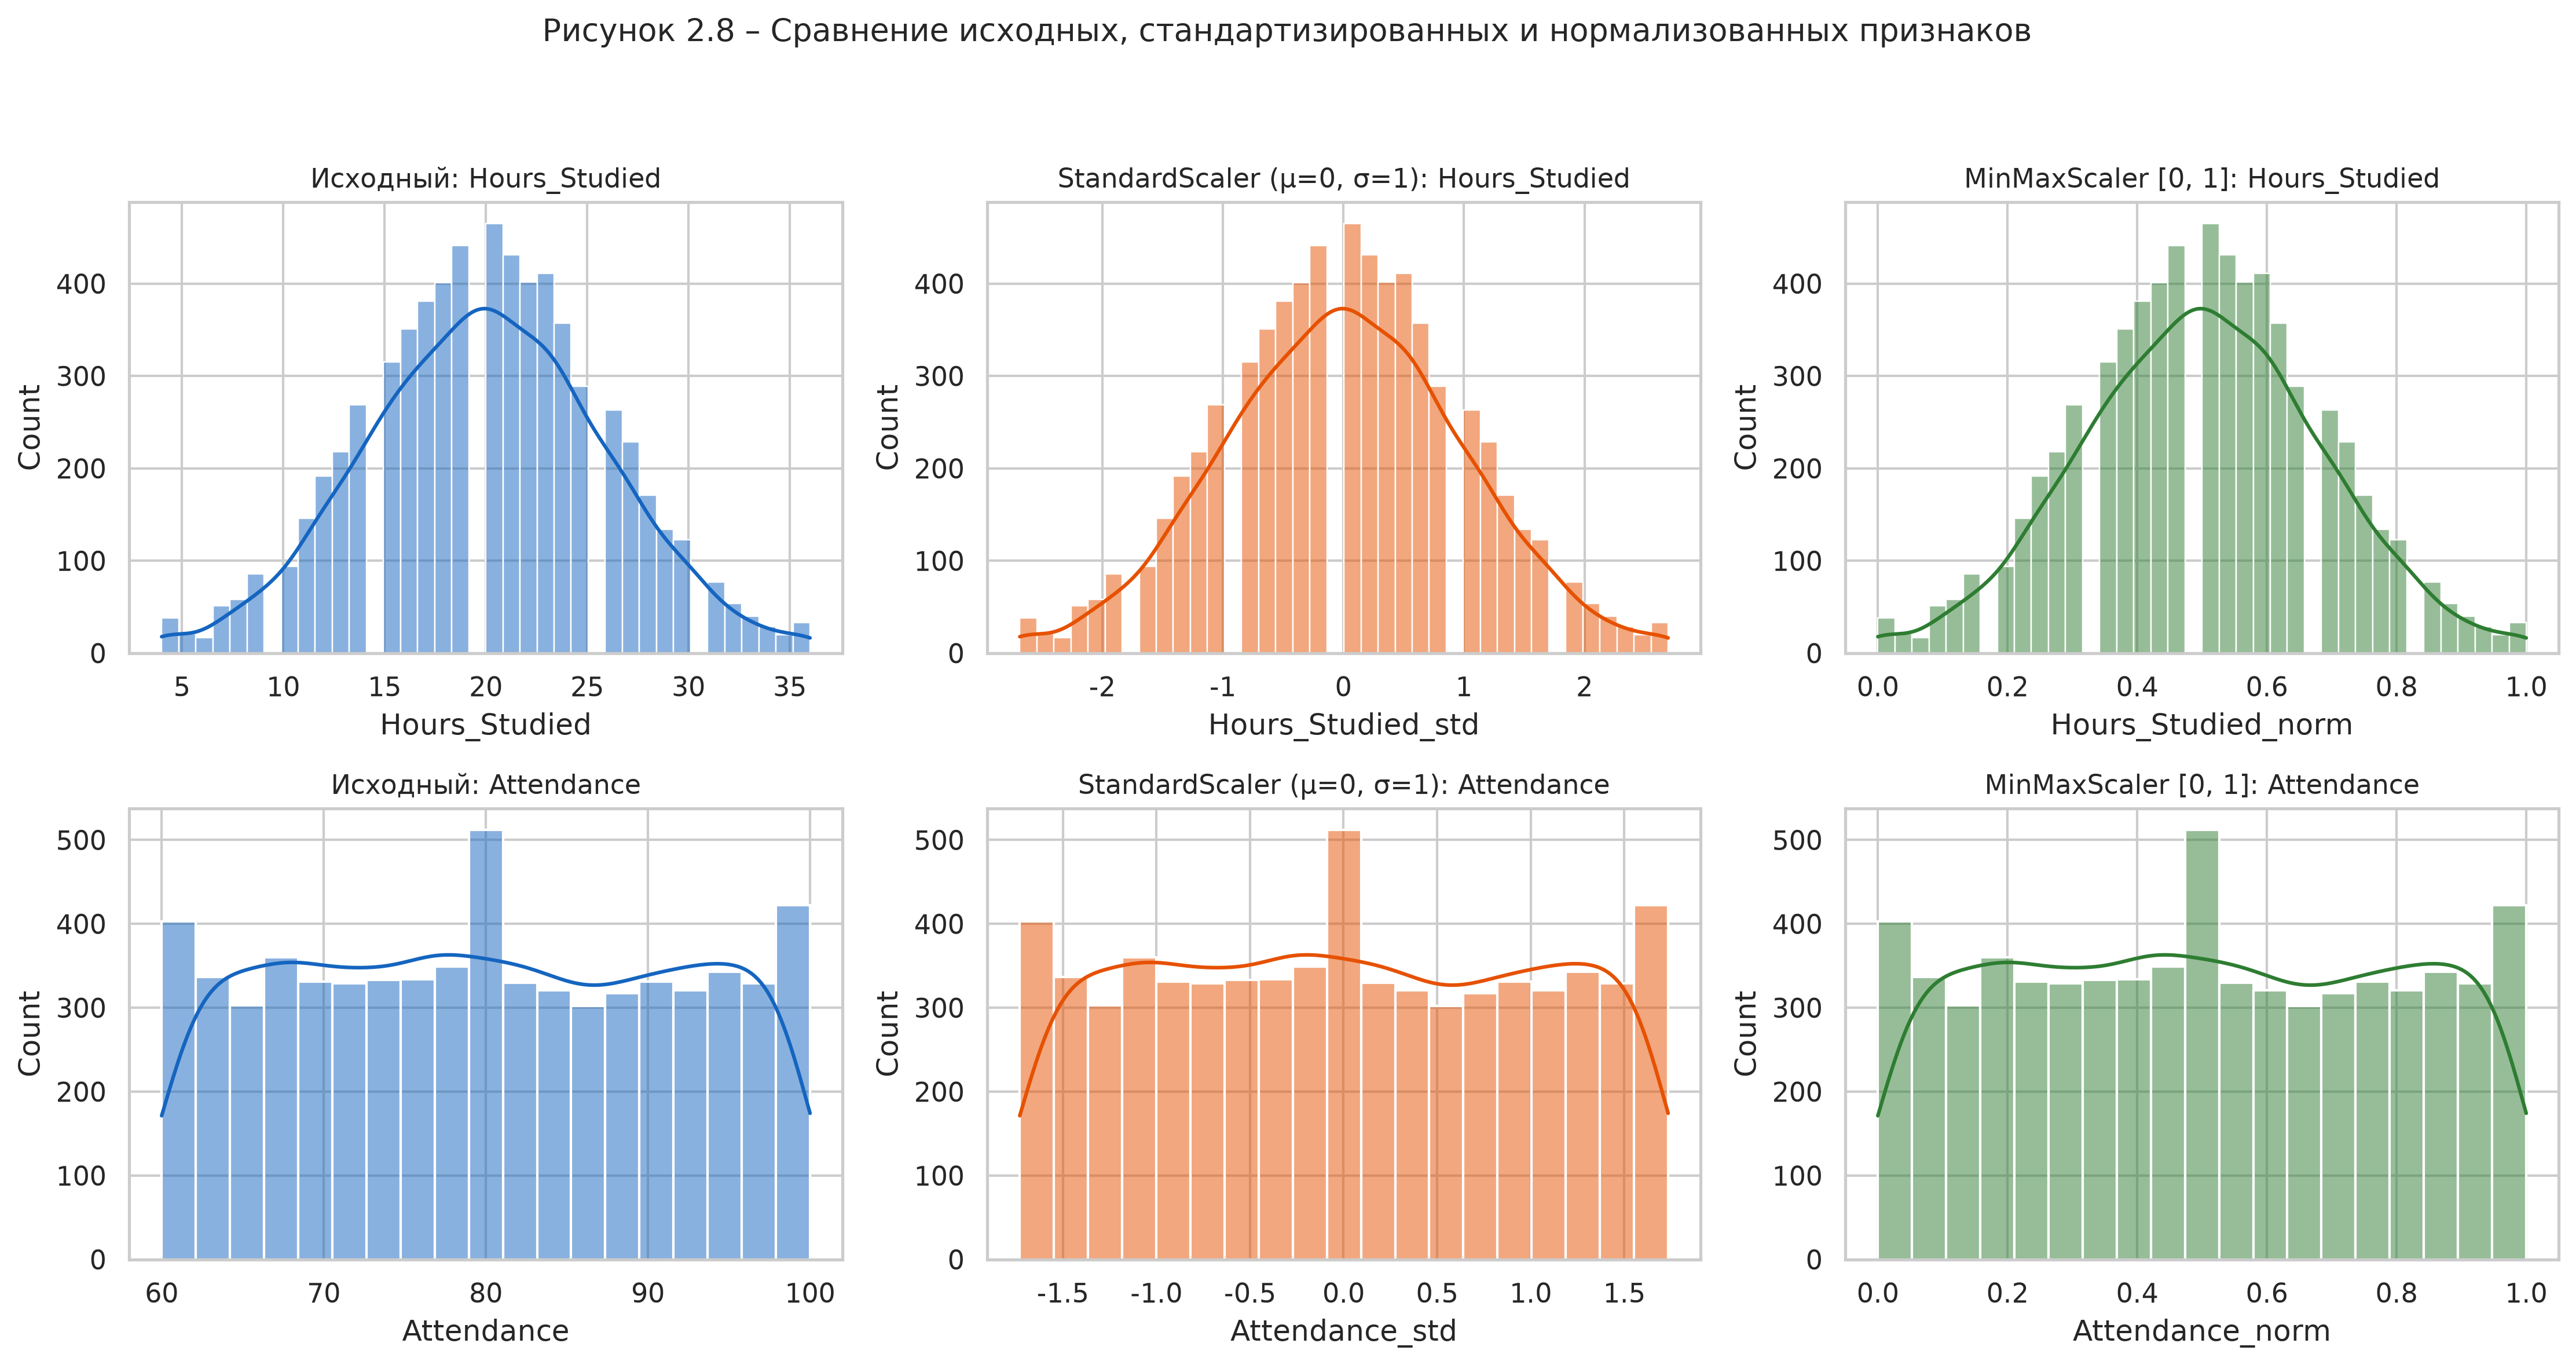

In [10]:
all_num_features = num_cols + new_cols

# 1. Стандартизация StandardScaler
std_scaler = StandardScaler()
df_std = df_encoded.copy()
df_std[[f + '_std' for f in all_num_features]] = std_scaler.fit_transform(df_encoded[all_num_features])

# 2. Нормализация MinMaxScaler
minmax_scaler = MinMaxScaler()
df_norm = df_encoded.copy()
df_norm[[f + '_norm' for f in all_num_features]] = minmax_scaler.fit_transform(df_encoded[all_num_features])

print('Сравнение параметров Hours_Studied:')
print(f'Исходный : mean={df_encoded["Hours_Studied"].mean():.2f}, std={df_encoded["Hours_Studied"].std():.2f}, min={df_encoded["Hours_Studied"].min()}, max={df_encoded["Hours_Studied"].max()}')
print(f'Standard : mean={df_std["Hours_Studied_std"].mean():.2f}, std={df_std["Hours_Studied_std"].std():.2f}, min={df_std["Hours_Studied_std"].min():.2f}, max={df_std["Hours_Studied_std"].max():.2f}')
print(f'MinMax   : mean={df_norm["Hours_Studied_norm"].mean():.2f}, std={df_norm["Hours_Studied_norm"].std():.2f}, min={df_norm["Hours_Studied_norm"].min():.2f}, max={df_norm["Hours_Studied_norm"].max():.2f}')


### 4.2. Корреляционный анализ числовых признаков

Построим матрицу парных коэффициентов корреляции Пирсона для оценки взаимосвязи между всеми числовыми признаками, включая синтезированные переменные и целевой показатель `Exam_Score`.


Корреляция с целевой переменной Exam_Score:
Exam_Score               1.00
Academic_Effort_Index    0.77
Attendance               0.66
Hours_Studied            0.50
Study_to_Sleep_Ratio     0.40
Previous_Scores          0.20
Tutoring_Sessions        0.17
Score_Growth             0.04
Physical_Activity        0.04
Sleep_Hours             -0.01
Name: Exam_Score, dtype: float64


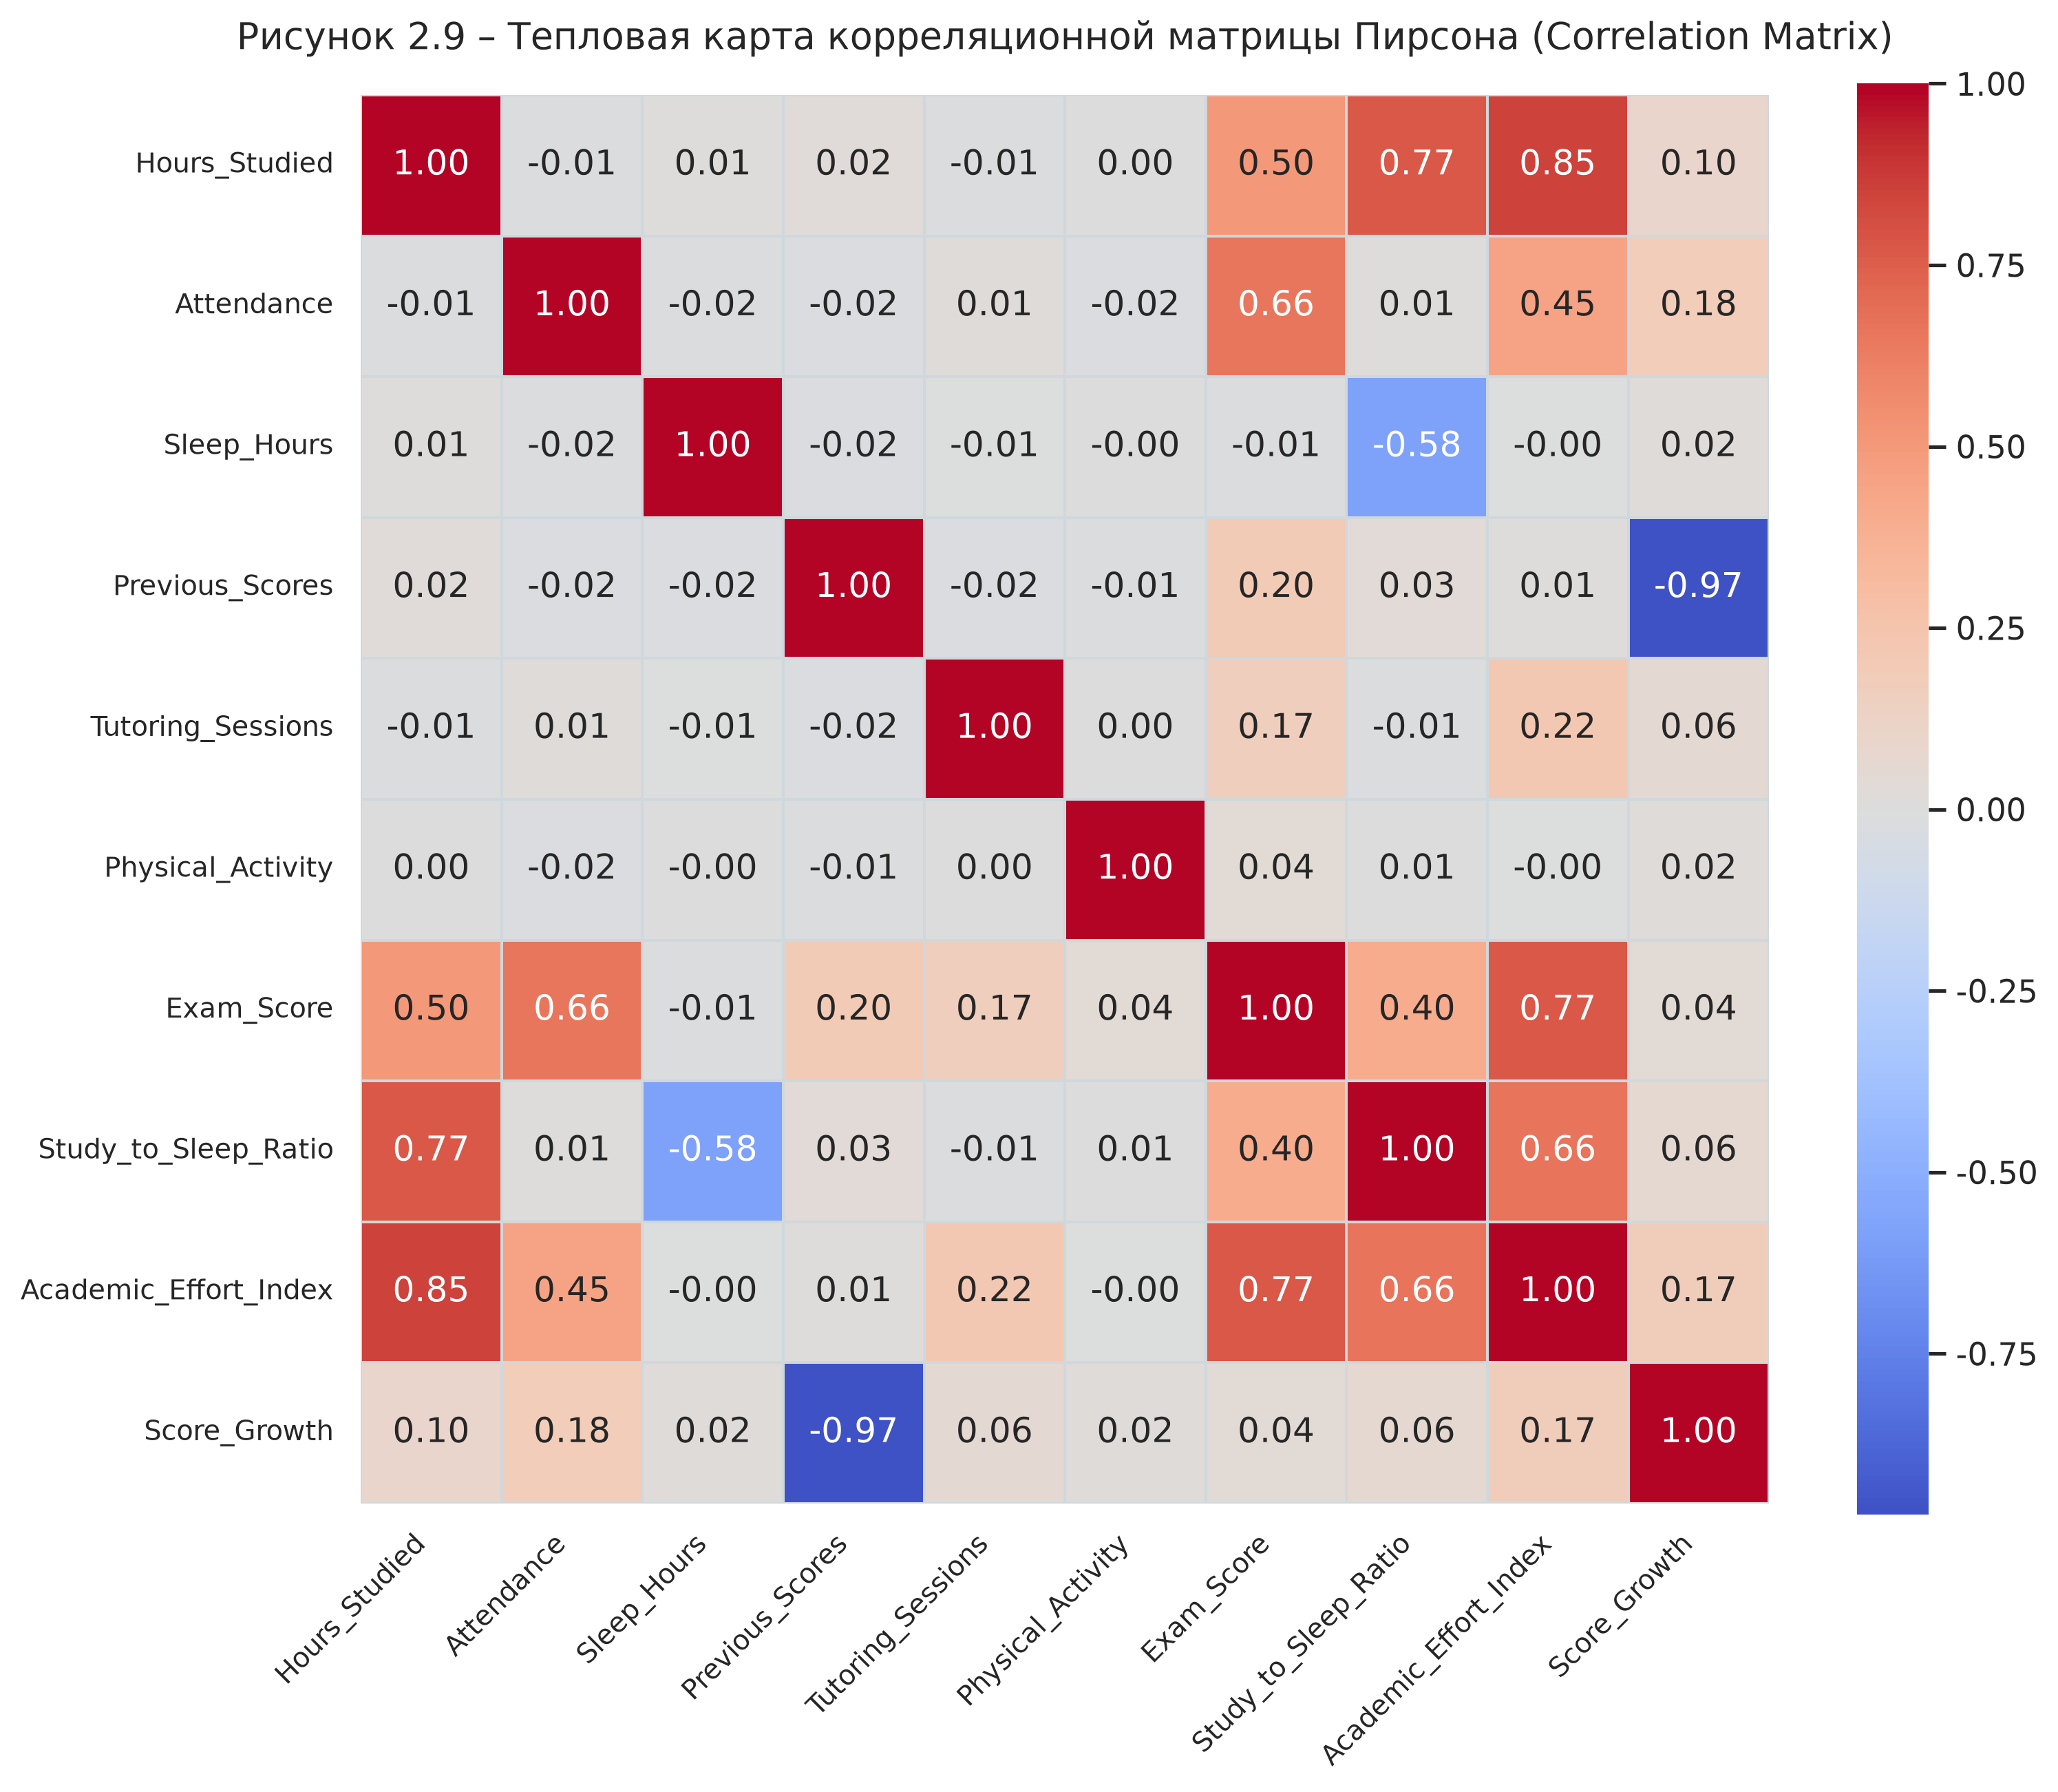

In [11]:
plt.figure(figsize=(11, 9))
corr_matrix = df_encoded[all_num_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar=True, square=True)
plt.xticks(rotation=45, ha='right')
plt.title('Рисунок 2.9 – Тепловая карта корреляционной матрицы Пирсона', fontsize=12)
plt.tight_layout()
plt.show()

print('Корреляция с целевой переменной Exam_Score:')
print(corr_matrix['Exam_Score'].sort_values(ascending=False).round(2))


## Выводы по лабораторной работе

В ходе выполнения лабораторной работы был успешно проведен комплексный разведочный анализ данных (EDA) и предобработка датасета успеваемости учащихся `StudentPerformanceFactors.csv`:

1. **Обнаружение и устранение пропусков:** С помощью статистических методов и тепловой карты пропусков выявлены пропущенные значения в признаках `Teacher_Quality` (78), `Parental_Education_Level` (90) и `Distance_from_Home` (67). Все 235 пропусков устранены подстановкой категориальной моды без искажения формы распределений.
2. **Обнаружение и устранение аномалий:** Методом межквартильного размаха (правило Тьюки) выявлены выбросы в признаках `Hours_Studied`, `Tutoring_Sessions` и `Exam_Score` (включая невозможный балл 101). Выбросы скорректированы винзоризацией по границам $Q_1 - 1.5 \cdot IQR$ и $Q_3 + 1.5 \cdot IQR$, что подтверждено контрольными диаграммами BoxPlot.
3. **Конструирование признаков:** Разработаны 3 новых содержательных признака (`Study_to_Sleep_Ratio`, `Academic_Effort_Index`, `Score_Growth`), причем `Academic_Effort_Index` показал наивысшую корреляцию с экзаменационным баллом ($r = +0.77$).
4. **Кодирование качественных данных:** Реализована бинаризация 5 дихотомических признаков в $\{0, 1\}$ и One-Hot Encoding для 8 категориальных признаков с защитой от ловушки фиктивных переменных (`drop_first=True`), расширив матрицу признаков до 31 столбца.
5. **Масштабирование:** Выполнена стандартизация (`StandardScaler`, $\mu=0, \sigma=1$) и нормализация (`MinMaxScaler`, $[0, 1]$), подготовив итоговый датасет к обучению любых классификационных и регрессионных моделей машинного обучения.
